# Kredi Kartı Dolandırıcılık Tespiti

Kaggle **Credit Card Fraud Detection** (ULB) verisiyle uçtan uca bir sınıflandırma projesi.
Veri, Eylül 2013'te Avrupalı kart sahiplerinin iki günlük 284.807 işlemi; yalnızca 492'si
dolandırıcılık (%0,17). `V1`–`V28` gizlilik için PCA'dan geçirilmiş. `Time` ilk işlemden bu yana
geçen saniye, `Amount` tutar, `Class` hedef (1 = dolandırıcılık).

**Kurallar:** Her yerde `random_state=42`. Scaler, SMOTE ve undersampling yalnızca train'e fit
edilir (leakage yok). Model ve eşik validation'da seçilir, test seti en sonda bir kez kullanılır.

## 0. Kurulum

Kütüphaneler ve sabitler. Grafiklerde **mavi = normal**, **turuncu = dolandırıcılık**.

In [1]:
import time
from pathlib import Path

import imblearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import RobustScaler
from xgboost import XGBClassifier

# Tekrarlanabilirlik için tek bir sabit
RANDOM_STATE = 42

# Grafik renkleri: sınıf başına sabit renk
COLOR_NORMAL = "#2a78d6"  # mavi
COLOR_FRAUD = "#eb6834"   # turuncu
COLOR_THIRD = "#1baf7a"   # su yeşili (üçüncü seri gerektiğinde)
COLOR_MUTED = "#8a8984"   # referans çizgileri için gri
SERIES_COLORS = [COLOR_NORMAL, COLOR_FRAUD, COLOR_THIRD]
CLASS_PALETTE = {"Normal": COLOR_NORMAL, "Dolandırıcılık": COLOR_FRAUD}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.4f}".format)

for lib in (pd, np, sklearn, imblearn, xgboost, sns):
    print(f"{lib.__name__:<16} {lib.__version__}")

pandas           3.1.1
numpy            2.5.5
sklearn          1.9.1
imblearn         0.14.2
xgboost          3.4.1
seaborn          0.13.2


In [2]:
# Veri dosyasının yolu: notebook ile aynı dizindeki data/ klasörü
DATA_PATH = Path("data") / "creditcard.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Veri dosyası bulunamadı: {DATA_PATH.resolve()}\n"
        "Çözüm: creditcard.csv dosyasını Kaggle'dan indirin "
        "(https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) ve bu notebook'un "
        "bulunduğu dizinde 'data/creditcard.csv' yoluna koyun.\n"
        "kagglehub ile indirme komutu README.md dosyasının 'Dataset' bölümünde."
    )

df = pd.read_csv(DATA_PATH)
print(f"Satır: {df.shape[0]:,}   Sütun: {df.shape[1]}")
df.head()

Satır: 284,807   Sütun: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 1. Keşifsel Veri Analizi (EDA)

Model kurmadan önce veriyi tanıyoruz. Burada gördüklerimiz metrik ve ön işleme kararlarını
belirleyecek.

### 1.1 Veri yapısı

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
# V sütunları PCA çıktısı olduğu için ortalamaları ~0'dır; Time ve Amount ise ham ölçekte.
df[["Time", "V1", "V2", "V3", "Amount", "Class"]].describe()

,Time,V1,V2,V3,Amount,Class
count,284807.0000,284807.0000,284807.0000,284807.0000,284807.0000,284807.0000
mean,94813.8596,0.0000,0.0000,-0.0000,88.3496,0.0017
std,47488.1460,1.9587,1.6513,1.5163,250.1201,0.0415
min,0.0000,-56.4075,-72.7157,-48.3256,0.0000,0.0000
25%,54201.5000,-0.9204,-0.5985,-0.8904,5.6000,0.0000
50%,84692.0000,0.0181,0.0655,0.1798,22.0000,0.0000
75%,139320.5000,1.3156,0.8037,1.0272,77.1650,0.0000
max,172792.0000,2.4549,22.0577,9.3826,25691.1600,1.0000


**Gözlem:** `V` sütunları PCA çıktısı olduğu için ortalamaları ~0. `Time` (0–172.792 sn ≈ 48 saat)
ve `Amount` (0–25.691) ise çok farklı ölçeklerde; bu yüzden 3. bölümde ölçeklenecekler.

### 1.2 Eksik değerler

In [5]:
missing = df.isna().sum()
print(f"Toplam eksik değer: {missing.sum()}")
missing[missing > 0]

Toplam eksik değer: 0


Series([], dtype: int64)

Eksik değer yok, doldurma gerekmiyor.

### 1.3 Tekrar eden satırlar

Birebir aynı satırlar bazı örneklere fazladan ağırlık verir. Bir kopya train'e, diğeri test'e
düşerse de skor şişer. Bu yüzden tekrarları **bölmeden önce** siliyoruz. Bu adım veriden
istatistik öğrenmediği için leakage yaratmaz.

In [6]:
dup_mask = df.duplicated(keep="first")
print(f"Tekrar eden satır sayısı: {dup_mask.sum():,}")
print("Tekrar eden satırların sınıf dağılımı:")
print(df.loc[dup_mask, "Class"].value_counts().rename(index={0: "Normal", 1: "Dolandırıcılık"}))

rows_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"\nSilmeden önce: {rows_before:,} satır  ->  sonra: {len(df):,} satır")

Tekrar eden satır sayısı: 1,081
Tekrar eden satırların sınıf dağılımı:
Class
Normal            1062
Dolandırıcılık      19
Name: count, dtype: int64



Silmeden önce: 284,807 satır  ->  sonra: 283,726 satır


### 1.4 Sınıf dağılımı

Projenin ana zorluğu: Dolandırıcılık işlemleri binde iki civarında.

,adet,oran (%)
Normal (0),283253,99.8333
Dolandırıcılık (1),473,0.1667


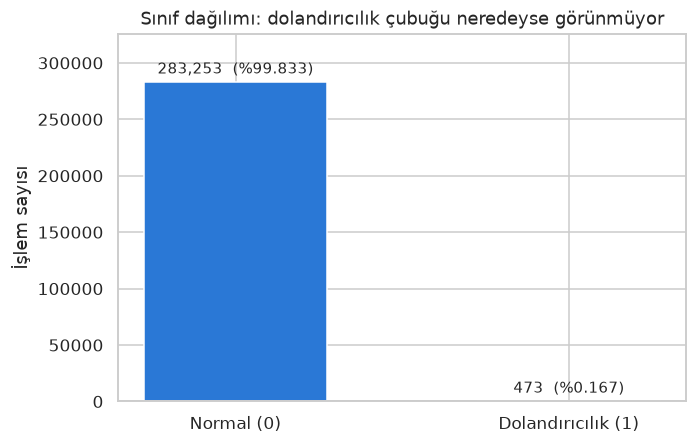

In [7]:
class_counts = df["Class"].value_counts().sort_index()
class_ratio = df["Class"].value_counts(normalize=True).sort_index()

class_table = pd.DataFrame({"adet": class_counts, "oran (%)": class_ratio * 100})
class_table.index = ["Normal (0)", "Dolandırıcılık (1)"]
display(class_table)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(class_table.index, class_counts.values, color=[COLOR_NORMAL, COLOR_FRAUD], width=0.55)
for bar, n, r in zip(bars, class_counts.values, class_ratio.values):
    ax.annotate(f"{n:,}  (%{r * 100:.3f})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.set_ylabel("İşlem sayısı")
ax.set_title("Sınıf dağılımı: dolandırıcılık çubuğu neredeyse görünmüyor")
plt.tight_layout()
plt.show()

**Her şeye "normal" diyen modelin accuracy'si:**

In [8]:
naive_accuracy = (df["Class"] == 0).mean()
print(f"Her işleme 'normal' diyen modelin accuracy'si: {naive_accuracy:.4%}")
print(f"Bu modelin yakaladığı dolandırıcılık: 0 / {class_counts.loc[1]}")

Her işleme 'normal' diyen modelin accuracy'si: 99.8333%
Bu modelin yakaladığı dolandırıcılık: 0 / 473


**Neden yanıltıcı?** Bu model %99,8 accuracy alıyor ama **tek bir dolandırıcılığı bile
yakalamıyor**. Normal işlemler ezici çoğunlukta olduğu için accuracy, azınlık sınıftaki başarıyı
neredeyse hiç yansıtmaz. Bu yüzden precision, recall, F1 ve PR-AUC kullanacağız.

### 1.5 İşlem tutarı (`Amount`)

Tutar çok sağa çarpık olduğu için `log(1 + Amount)` çiziyoruz. `+1` sıfır tutarlar içindir.
`common_norm=False` her sınıfı kendi içinde normalize eder, böylece şekiller karşılaştırılabilir.

,count,mean,std,min,25%,50%,75%,95%,max
Class,,,,,,,,,
Normal,283253.0000,88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,365.0000,25691.1600
Dolandırıcılık,473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,655.8200,2125.8700


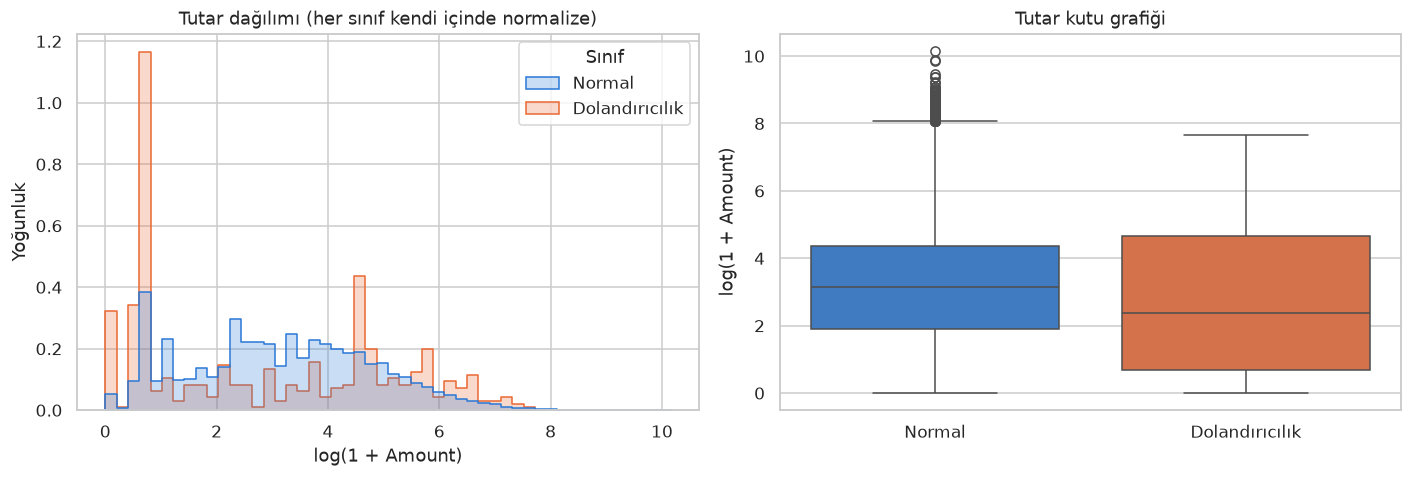

In [9]:
CLASS_NAMES = {0: "Normal", 1: "Dolandırıcılık"}

amount_stats = df.groupby("Class")["Amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])
amount_stats.index = amount_stats.index.map(CLASS_NAMES)
display(amount_stats)

plot_df = pd.DataFrame({
    "Sınıf": df["Class"].map(CLASS_NAMES),
    "log_amount": np.log1p(df["Amount"]),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=plot_df, x="log_amount", hue="Sınıf", stat="density", common_norm=False,
             bins=50, element="step", palette=CLASS_PALETTE, ax=axes[0])
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Yoğunluk")
axes[0].set_title("Tutar dağılımı (her sınıf kendi içinde normalize)")

sns.boxplot(data=plot_df, x="Sınıf", y="log_amount", hue="Sınıf", palette=CLASS_PALETTE,
            legend=False, ax=axes[1])
axes[1].set_xlabel("")
axes[1].set_ylabel("log(1 + Amount)")
axes[1].set_title("Tutar kutu grafiği")
plt.tight_layout()
plt.show()

**Gözlem:** Dolandırıcılığın medyan tutarı daha düşük, ama dağılımı daha geniş: Çok küçük
"deneme" işlemleriyle birkaç yüz birimlik işlemler bir arada. Tutar tek başına ayırt edici değil.

### 1.6 Günün saati

`(Time // 3600) % 24` ile saati çıkarıyoruz. Verinin gece yarısı başladığını varsayıyoruz; gece
düşen işlem hacmi bu varsayımı destekliyor.

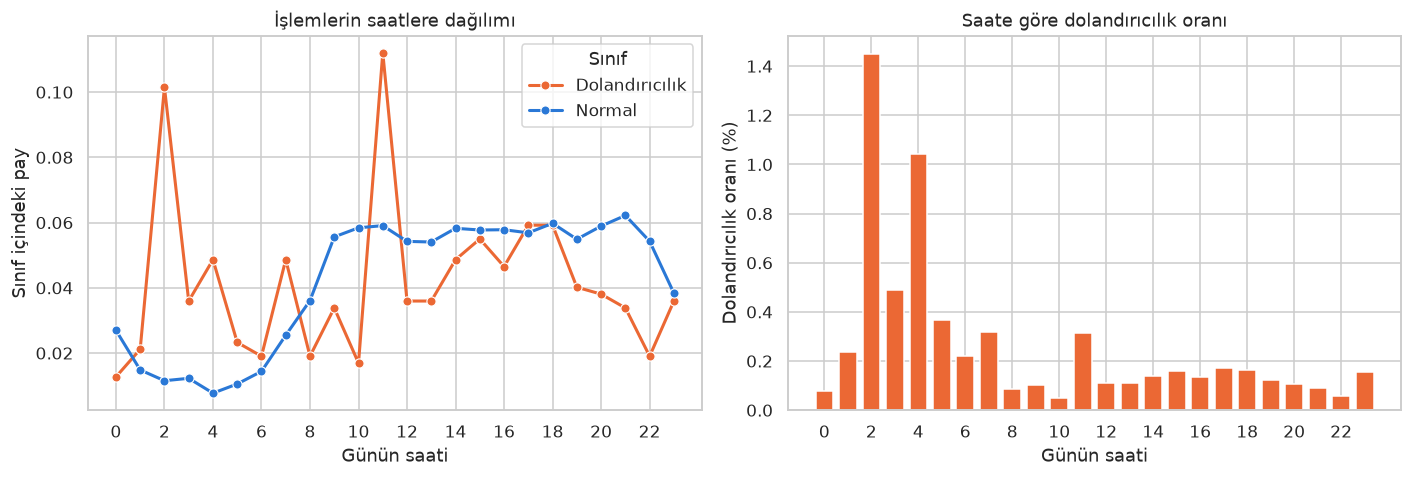

Dolandırıcılık oranının en yüksek olduğu saat: 2 (%1.45, genel oran %0.17)


In [10]:
df_eda = df.assign(
    Hour=(df["Time"] // 3600 % 24).astype(int),
    Sınıf=df["Class"].map(CLASS_NAMES),
)

# Her sınıfın işlemlerinin saatlere göre payı (sınıf içinde normalize)
hour_share = (
    df_eda.groupby("Sınıf")["Hour"].value_counts(normalize=True)
    .rename("pay").reset_index()
)
# Her saatte işlemlerin yüzde kaçı dolandırıcılık
fraud_rate_by_hour = df_eda.groupby("Hour")["Class"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=hour_share, x="Hour", y="pay", hue="Sınıf", palette=CLASS_PALETTE,
             marker="o", linewidth=2, ax=axes[0])
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Günün saati")
axes[0].set_ylabel("Sınıf içindeki pay")
axes[0].set_title("İşlemlerin saatlere dağılımı")

axes[1].bar(fraud_rate_by_hour.index, fraud_rate_by_hour.values, color=COLOR_FRAUD, width=0.75)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Günün saati")
axes[1].set_ylabel("Dolandırıcılık oranı (%)")
axes[1].set_title("Saate göre dolandırıcılık oranı")
plt.tight_layout()
plt.show()

print(f"Dolandırıcılık oranının en yüksek olduğu saat: {fraud_rate_by_hour.idxmax()} "
      f"(%{fraud_rate_by_hour.max():.2f}, genel oran %{df['Class'].mean() * 100:.2f})")

**Gözlem:** Normal işlemler gece azalıyor, dolandırıcılık azalmıyor (saat 2'de belirgin bir tepe
var). Bu yüzden gece saatlerinde dolandırıcılık oranı çok daha yüksek. Pozitif örnek az olduğu
için tek tek tepeleri fazla yorumlamamak gerekir.

### 1.7 `Class` ile en ilişkili V özellikleri

Her `V` sütununun `Class` ile korelasyonuna bakıyoruz: İşaret ilişkinin yönünü, mutlak değer
gücünü gösterir. Bu yalnızca keşif amaçlı; buna göre özellik seçmediğimiz için leakage yok.

,Class ile korelasyon
V17,-0.3135
V14,-0.2934
V12,-0.2507
V10,-0.2070
V16,-0.1872
V3,-0.1823
V7,-0.1723
V11,0.1491
V4,0.1293
V18,-0.1053


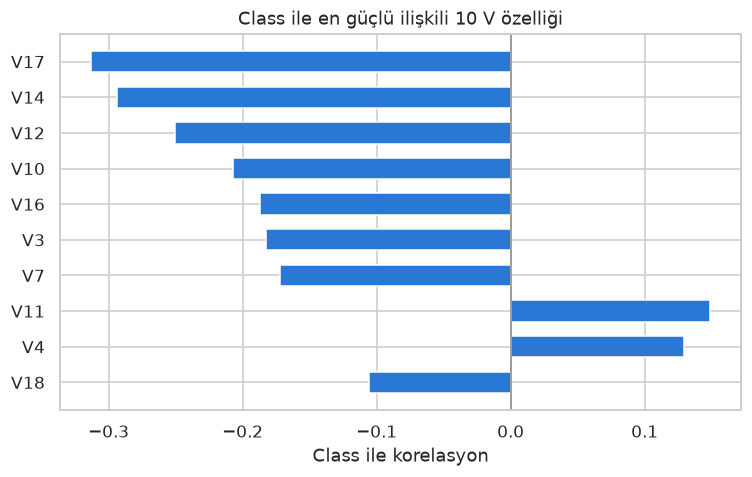

In [11]:
v_cols = [f"V{i}" for i in range(1, 29)]
corr_with_class = df[v_cols].corrwith(df["Class"]).sort_values(key=np.abs, ascending=False)
top_corr = corr_with_class.head(10)
display(top_corr.to_frame("Class ile korelasyon"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=COLOR_NORMAL, height=0.6)
ax.axvline(0, color=COLOR_MUTED, linewidth=1)
ax.set_xlabel("Class ile korelasyon")
ax.set_title("Class ile en güçlü ilişkili 10 V özelliği")
plt.tight_layout()
plt.show()

En güçlü 4 özelliğin sınıflara göre dağılımı (ne kadar az örtüşürse o kadar ayırt edici):

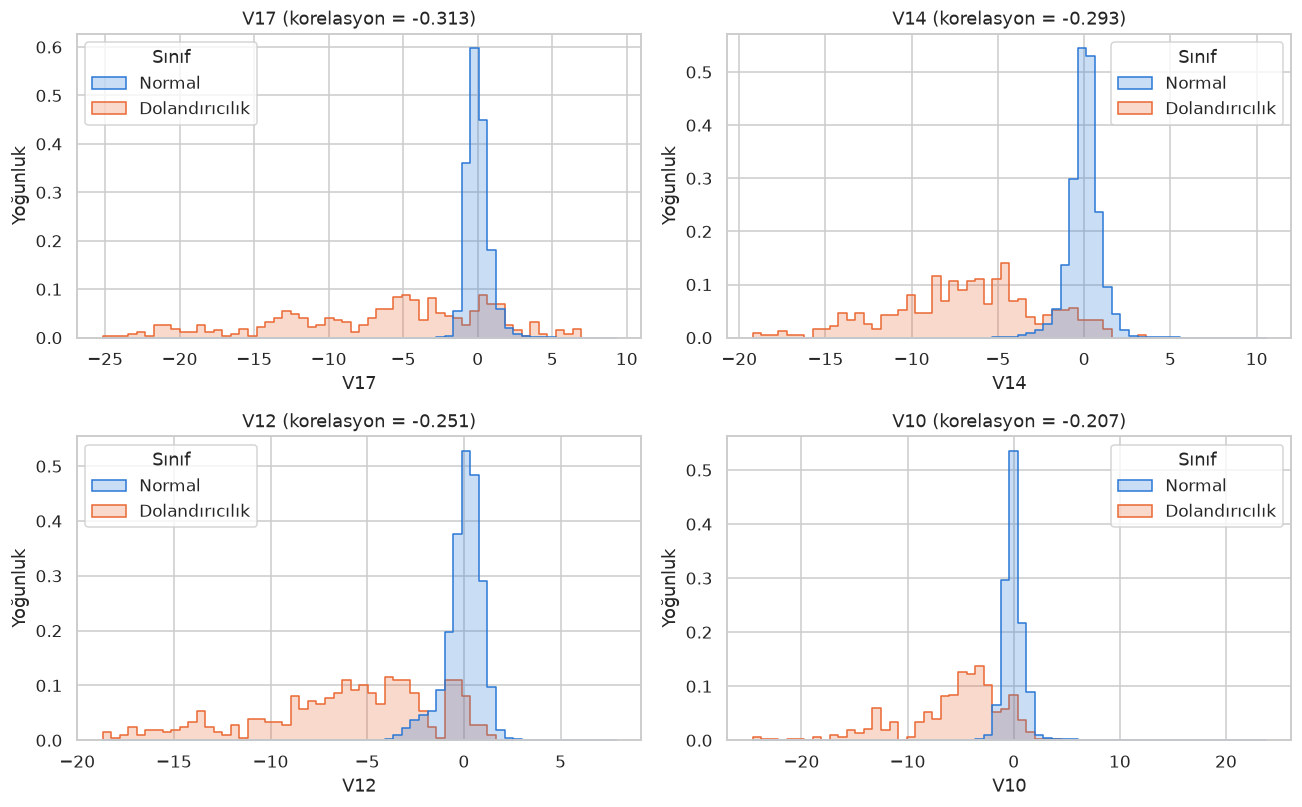

In [12]:
top4 = top_corr.index[:4].tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, feat in zip(axes.ravel(), top4):
    sns.histplot(data=df_eda, x=feat, hue="Sınıf", stat="density", common_norm=False,
                 bins=60, element="step", palette=CLASS_PALETTE, ax=ax)
    ax.set_title(f"{feat} (korelasyon = {corr_with_class[feat]:+.3f})")
    ax.set_ylabel("Yoğunluk")
plt.tight_layout()
plt.show()

**Gözlem:** `V14` ve `V17` gibi özelliklerde dolandırıcılık belirgin şekilde kaymış, ama kuyruklar
örtüşüyor. Tek bir özellik yetmiyor; model bunları birlikte kullanmalı.

**EDA özeti:** Eksik değer yok, 1.081 tekrar silindi. Sınıflar aşırı dengesiz. `Amount` çarpık,
`Time` ise farklı bir ölçekte. Gece dolandırıcılık oranı yüksek. `V14`, `V17`, `V12` ve `V10`
güçlü ayırıcılar.

## 2. Train / Validation / Test Bölmesi

- **Train (%60):** Eğitim. Scaler ve SMOTE da yalnızca buna fit edilir.
- **Validation (%20):** Model ve eşik seçimi.
- **Test (%20):** En sonda bir kez kullanılır; tarafsız performans tahmini verir.

Seçimi test setinde yapsaydık test skoru iyimser olurdu. `stratify=y` her setteki sınıf oranını
korur; nadir sınıfta bu şart. Önce %20 test ayırıyoruz, sonra kalanın %25'ini validation
yapıyoruz (0,8 × 0,25 = 0,2).

In [13]:
X = df.drop(columns="Class")
y = df["Class"]

# 1. adım: %20 test
X_temp, X_test_raw, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
# 2. adım: kalan %80'in %25'i validation, yani toplamın %20'si
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame(
    {
        "satır": [len(s) for s in (y_train, y_val, y_test)],
        "pay (%)": [len(s) / len(y) * 100 for s in (y_train, y_val, y_test)],
        "dolandırıcılık": [int(s.sum()) for s in (y_train, y_val, y_test)],
        "dolandırıcılık oranı (%)": [s.mean() * 100 for s in (y_train, y_val, y_test)],
    },
    index=["train", "validation", "test"],
)
split_summary

,satır,pay (%),dolandırıcılık,dolandırıcılık oranı (%)
train,170235,59.9998,284,0.1668
validation,56745,19.9999,94,0.1657
test,56746,20.0003,95,0.1674


Oranlar üç sette de aynı. Validation ve test setlerinde yalnızca ~95 dolandırıcılık var;
metrikler birkaç işlemle bile oynayabilir.

## 3. Ölçekleme

`V1`–`V28` zaten benzer ölçekte, bu yüzden yalnızca `Time` ve `Amount`'u ölçekliyoruz. Logistic
Regression ölçeğe duyarlıdır, ağaç modelleri değildir; yine de tüm modellere aynı girdiyi
veriyoruz.

**Neden RobustScaler?** `(x − medyan) / IQR` formülünü kullanır. Medyan ve IQR uç değerlerden
etkilenmez. `Amount`'un medyanı ~22, maksimumu ~25.691. StandardScaler (ortalama/std) ve
MinMaxScaler (min/max) bu uç değerlerle bozulur.

**Leakage:** Scaler yalnızca train'e `fit` edilir, diğer setlere sadece `transform` uygulanır.
`*_raw` kopyalarını maliyet ve tutar analizi için saklıyoruz.

In [14]:
SCALE_COLS = ["Time", "Amount"]

scaler = RobustScaler()
scaler.fit(X_train_raw[SCALE_COLS])  # yalnızca train'e fit


def scale_features(X_raw):
    # Ham veriyi kopyalayıp yalnızca Time ve Amount sütunlarını ölçekler
    X_scaled = X_raw.copy()
    X_scaled[SCALE_COLS] = scaler.transform(X_raw[SCALE_COLS])
    return X_scaled


X_train = scale_features(X_train_raw)
X_val = scale_features(X_val_raw)
X_test = scale_features(X_test_raw)

for col, center, iqr in zip(SCALE_COLS, scaler.center_, scaler.scale_):
    print(f"{col:<7} train medyanı = {center:>10,.2f}   train IQR = {iqr:>10,.2f}")

pd.concat(
    {"önce (ham)": X_train_raw[SCALE_COLS].describe(), "sonra (RobustScaler)": X_train[SCALE_COLS].describe()},
    axis=1,
)

Time    train medyanı =  84,965.00   train IQR =  85,136.00
Amount  train medyanı =      22.04   train IQR =      71.89


önce (ham)             sonra (RobustScaler)            
             Time      Amount                 Time      Amount
count 170235.0000 170235.0000          170235.0000 170235.0000
mean   94935.8569     88.1606               0.1171      0.9197
std    47513.4767    246.4499               0.5581      3.4279
min        0.0000      0.0000              -0.9980     -0.3066
25%    54203.0000      5.6800              -0.3613     -0.2276
50%    84965.0000     22.0400               0.0000      0.0000
75%   139339.0000     77.5750               0.6387      0.7724
max   172788.0000  19656.5300               1.0316    273.0995

Ölçeklemeden sonra `Amount`'un medyanı 0, IQR'ı 1. Uç değerler kırpılmaz, ama artık ölçeği
belirleyen onlar değil.

## 4. Metrikler

Pozitif sınıf = dolandırıcılık:

|  | Tahmin: Normal | Tahmin: Dolandırıcılık |
|---|---|---|
| **Gerçek: Normal** | TN | **FP:** yanlış alarm, müşteri rahatsız edilir |
| **Gerçek: Dolandırıcılık** | **FN:** kaçırılan işlem, para kaybı | TP: yakalanan |

- **Precision = TP / (TP + FP):** Alarmların yüzde kaçı gerçek dolandırıcılık?
- **Recall = TP / (TP + FN):** Dolandırıcılıkların yüzde kaçını yakaladık?
- **F1:** İkisinin harmonik ortalaması; küçük olanı cezalandırır.

Örnek: 95 dolandırıcılık var, model 100 alarm veriyor ve bunların 80'i doğru. Precision 0,80,
recall 0,84 olur.

Model 0–1 arası bir skor üretir; skor bir **eşikle** (varsayılan 0,5) karara çevrilir. Eşik
düşerse recall artar, precision düşer; eşiği 7. bölümde seçeceğiz. Eşikten bağımsız iki özet
metrik de var: **ROC-AUC** ve **PR-AUC** (6. bölüm). Aşağıdaki fonksiyonlar tüm modelleri aynı
şekilde değerlendirir.

In [15]:
def compute_metrics(name, y_true, y_score, threshold=0.5):
    # Olasılık skorlarını eşikle sınıfa çevirip tüm metrikleri tek sözlükte döndürür
    y_true = np.asarray(y_true)
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "eşik": threshold,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
    }


def plot_confusion(y_true, y_pred, title, ax=None):
    # Confusion matrix'i sınıf isimleriyle çizer
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1], display_labels=["Normal", "Dolandırıcılık"],
        cmap="Blues", values_format="d", colorbar=False, ax=ax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Tahmin")
    ax.set_ylabel("Gerçek")
    ax.grid(False)
    if show:
        plt.tight_layout()
        plt.show()


def evaluate(name, model, X, y_true, threshold=0.5, show_cm=False):
    # Eğitilmiş bir modeli verilen sette değerlendirir; metrikleri ve skorları döndürür
    y_score = model.predict_proba(X)[:, 1]  # dolandırıcılık sınıfının olasılığı
    metrics = compute_metrics(name, y_true, y_score, threshold)
    if show_cm:
        plot_confusion(y_true, (y_score >= threshold).astype(int), f"{name} (eşik = {threshold:.3f})")
    return metrics, y_score

## 5. Modeller

Her model train setinde eğitilir ve validation setinde 0,5 eşiğiyle değerlendirilir.

| Model | Fikir |
|---|---|
| **Dummy** | Her şeye "normal" der; taban çizgisi. |
| **LR** | Doğrusal model, dengeleme yok. |
| **LR + `class_weight`** | Dolandırıcılık hatalarını ~600 kat ağır sayar. |
| **LR + RandomUnderSampler** | Normal işlemleri atarak 1:1 dengeler; bilgi kaybeder. |
| **LR + SMOTE** | Azınlık sınıf için sentetik örnekler üretir. |
| **Random Forest** | Ağaçların oylaması; `class_weight`'li ve `class_weight`'siz. |
| **XGBoost** | Birbirinin hatasını düzelten ardışık ağaçlar; `scale_pos_weight = negatif / pozitif`. |

Örnekleyiciler bir `imblearn` Pipeline içinde. Yalnızca `fit` sırasında çalışırlar, validation
verisine dokunmazlar. `scale_pos_weight` de train setinden hesaplanıyor.

In [16]:
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
scale_pos_weight = n_neg / n_pos
print(f"Train: {n_neg:,} normal, {n_pos} dolandırıcılık  ->  scale_pos_weight = {scale_pos_weight:.1f}")

DUMMY_NAME = "Dummy (hep normal)"

models = {
    DUMMY_NAME: DummyClassifier(strategy="most_frequent"),
    "LR": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "LR + class_weight": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "LR + RandomUnderSampler": ImbPipeline([
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "LR + SMOTE": ImbPipeline([
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Random Forest + class_weight": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

Train: 169,951 normal, 284 dolandırıcılık  ->  scale_pos_weight = 598.4


In [17]:
val_results = []
val_scores = {}      # her modelin validation skorları (6. ve 7. bölümde kullanılacak)
fitted_models = {}   # eğitilmiş modeller

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)  # her model yalnızca train setiyle eğitilir
    elapsed = time.perf_counter() - start

    metrics, scores = evaluate(name, model, X_val, y_val)
    metrics["süre (sn)"] = elapsed
    val_results.append(metrics)
    val_scores[name] = scores
    fitted_models[name] = model
    print(f"{name:<30} PR-AUC={metrics['pr_auc']:.3f}  recall={metrics['recall']:.3f}  "
          f"precision={metrics['precision']:.3f}  ({elapsed:.1f} sn)")

Dummy (hep normal)             PR-AUC=0.002  recall=0.000  precision=0.000  (0.0 sn)


LR                             PR-AUC=0.803  recall=0.660  precision=0.886  (2.4 sn)


LR + class_weight              PR-AUC=0.786  recall=0.904  precision=0.054  (4.5 sn)


LR + RandomUnderSampler        PR-AUC=0.490  recall=0.915  precision=0.028  (0.1 sn)


LR + SMOTE                     PR-AUC=0.788  recall=0.904  precision=0.050  (7.4 sn)


Random Forest                  PR-AUC=0.877  recall=0.819  precision=0.939  (135.2 sn)


Random Forest + class_weight   PR-AUC=0.876  recall=0.840  precision=0.908  (57.5 sn)


XGBoost                        PR-AUC=0.890  recall=0.851  precision=0.930  (51.7 sn)


### Karşılaştırma tablosu (validation, eşik = 0,5)

Tablo PR-AUC'ye göre sıralı. PR-AUC eşikten bağımsızdır ve sıralama kalitesini ölçer; eşiği
zaten 7. bölümde ayarlayacağız. Her sütunun en iyi değeri vurgulu.

In [18]:
results_df = (
    pd.DataFrame(val_results)
    .set_index("model")
    .drop(columns="eşik")
    .sort_values("pr_auc", ascending=False)
)
metric_cols = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
(
    results_df.style
    .format({c: "{:.3f}" for c in metric_cols} | {"süre (sn)": "{:.1f}"})
    .highlight_max(subset=metric_cols, color="#cde2fb")
)

,TP,FP,FN,TN,precision,recall,f1,roc_auc,pr_auc,süre (sn)
model,,,,,,,,,,
XGBoost,80,6,14,56645,0.930,0.851,0.889,0.978,0.890,51.7
Random Forest,77,5,17,56646,0.939,0.819,0.875,0.955,0.877,135.2
Random Forest + class_weight,79,8,15,56643,0.908,0.840,0.873,0.960,0.876,57.5
LR,62,8,32,56643,0.886,0.660,0.756,0.976,0.803,2.4
LR + SMOTE,85,1608,9,55043,0.050,0.904,0.095,0.977,0.788,7.4
LR + class_weight,85,1493,9,55158,0.054,0.904,0.102,0.979,0.786,4.5
LR + RandomUnderSampler,86,3031,8,53620,0.028,0.915,0.054,0.974,0.490,0.1
Dummy (hep normal),0,0,94,56651,0.000,0.000,0.000,0.500,0.002,0.0


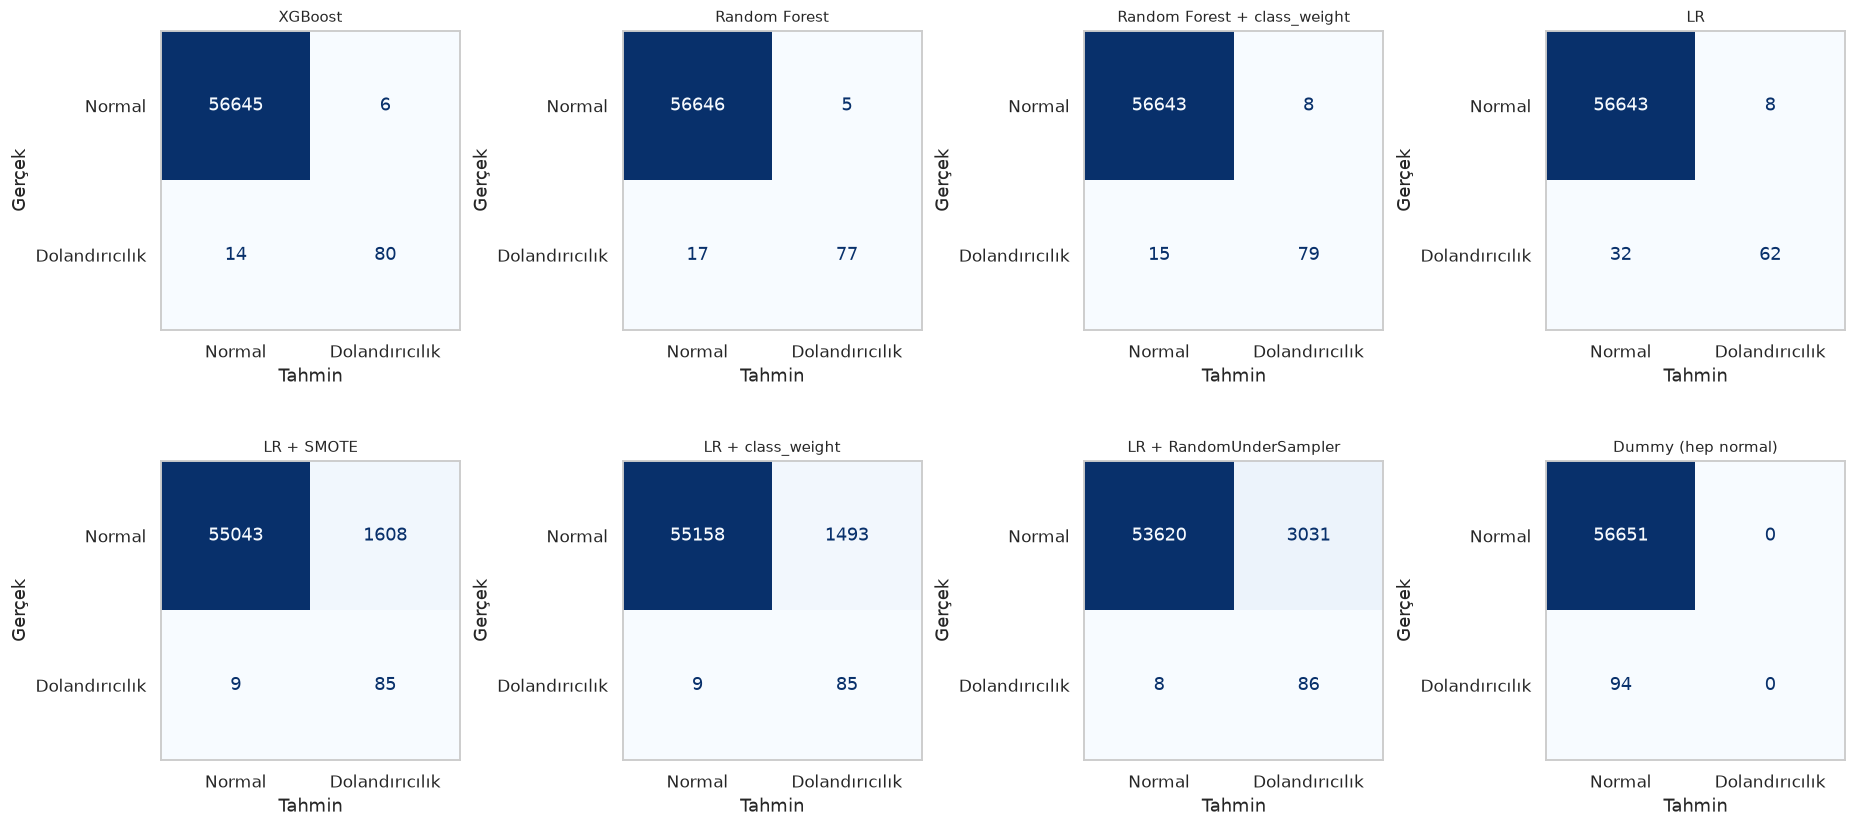

In [19]:
# Her modelin validation confusion matrix'i: precision/recall ödünleşimini görsel olarak gösterir
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, name in zip(axes.ravel(), results_df.index):
    y_pred = (val_scores[name] >= 0.5).astype(int)
    plot_confusion(y_val, y_pred, name, ax=ax)
plt.tight_layout()
plt.show()

**Tablodan çıkanlar**

- **Dummy:** Precision, recall ve F1 sıfır; PR-AUC dolandırıcılık oranına (~0,0017) eşit.
- **Dengelenmiş LR'ler** recall'u yükseltiyor, ama 0,5 eşiğinde binlerce yanlış alarm veriyor.
  PR-AUC'leri dengesiz LR'den yüksek değil: Dengeleme sıralamayı değil, 0,5 eşiğinin yerini
  değiştiriyor. Undersampling ise bilgi kaybı yüzünden PR-AUC'yi düşürüyor.
- **Ağaç modelleri** en yüksek PR-AUC'ye ulaşıyor.
- ~95 pozitif örnekle 0,01'lik farklar kesin üstünlük sayılmamalı.

## 6. ROC-AUC ve PR-AUC

İki eğri de eşiği 1'den 0'a kaydırarak çizilir:

- **ROC:** x = FPR (FP / tüm normal işlemler), y = recall. Rastgele model köşegendir (AUC 0,5).
- **PR:** x = recall, y = precision. Rastgele model, dolandırıcılık oranında (~0,0017) yatay bir
  çizgidir.

PR-AUC'ye göre en iyi 3 model:

En iyi 3 model (validation PR-AUC): ['XGBoost', 'Random Forest', 'Random Forest + class_weight']


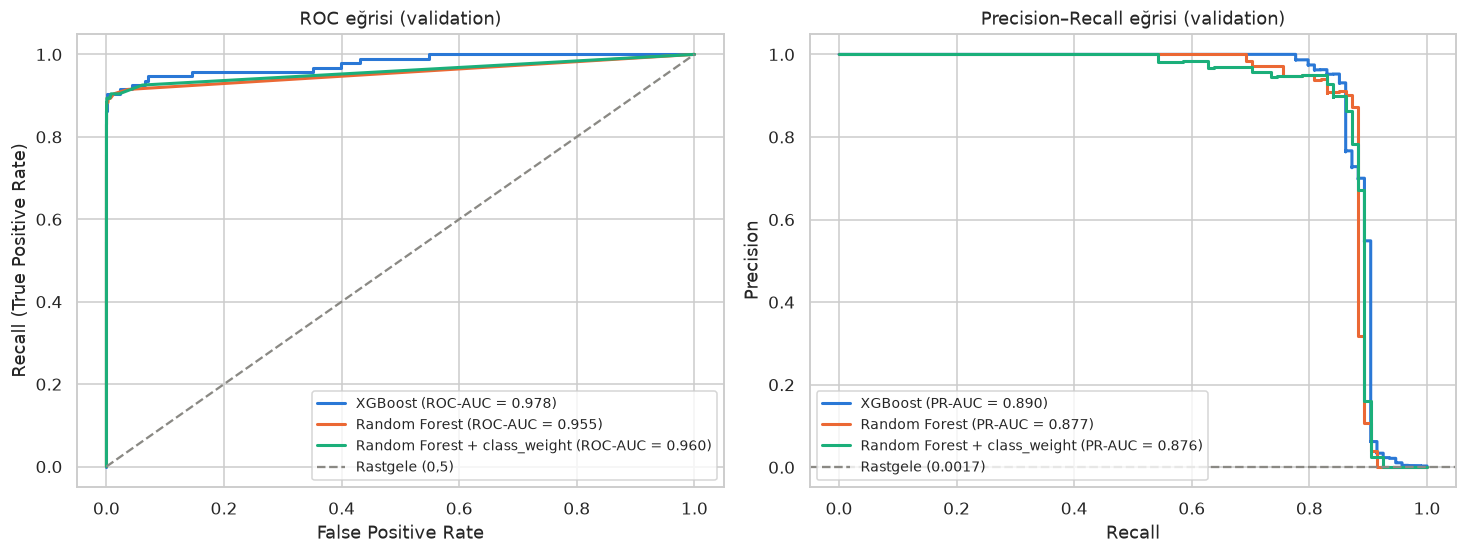

In [20]:
ranked = results_df.drop(index=DUMMY_NAME)
top3 = ranked.head(3).index.tolist()
print("En iyi 3 model (validation PR-AUC):", top3)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for name, color in zip(top3, SERIES_COLORS):
    fpr, tpr, _ = roc_curve(y_val, val_scores[name])
    axes[0].plot(fpr, tpr, color=color, linewidth=2,
                 label=f"{name} (ROC-AUC = {results_df.loc[name, 'roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_val, val_scores[name])
    axes[1].plot(rec, prec, color=color, linewidth=2, drawstyle="steps-post",
                 label=f"{name} (PR-AUC = {results_df.loc[name, 'pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color=COLOR_MUTED, label="Rastgele (0,5)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("Recall (True Positive Rate)")
axes[0].set_title("ROC eğrisi (validation)")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(y_val.mean(), linestyle="--", color=COLOR_MUTED,
                label=f"Rastgele ({y_val.mean():.4f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall eğrisi (validation)")
axes[1].legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**ROC-AUC dengesiz veride neden iyimser?** FPR'ın paydası ~57 bin normal işlem. Yüzlerce yanlış
alarm bile FPR'ı küçük bırakır; ROC-AUC 0,95–0,98'e çıkar ve modeller arasındaki farklar
kaybolur. Precision'ın paydası ise alarm sayısıdır (TP + FP), bu yüzden yanlış alarmlar
precision'ı doğrudan düşürür. Sayılarla görelim:

In [21]:
best_name = top3[0]
COMPARE_NAME = "LR + RandomUnderSampler"

# 1) ROC-AUC dar bir aralıkta toplanırken PR-AUC modelleri çok daha net ayırıyor
display(results_df.drop(index=DUMMY_NAME)[["roc_auc", "pr_auc"]].round(3))


def operating_point(y_true, y_score, target_recall):
    # Recall'un ilk kez hedefe ulaştığı noktadaki FPR, FP sayısı ve precision
    fpr, tpr, _ = roc_curve(y_true, y_score)
    idx = int(np.argmax(tpr >= target_recall))
    n_neg_, n_pos_ = int((y_true == 0).sum()), int((y_true == 1).sum())
    fp, tp = fpr[idx] * n_neg_, tpr[idx] * n_pos_
    return {"recall": tpr[idx], "FPR": fpr[idx], "FP sayısı": round(fp), "precision": tp / (tp + fp)}


# 2) Aynı recall'da iki model: FPR'lar ikisi için de "küçük", ama precision çok farklı
TARGET_RECALL = 0.85
pd.DataFrame(
    {name: operating_point(y_val, val_scores[name], TARGET_RECALL) for name in (best_name, COMPARE_NAME)}
).T.style.format({"recall": "{:.3f}", "FPR": "{:.4f}", "FP sayısı": "{:.0f}", "precision": "{:.3f}"})

,roc_auc,pr_auc
model,,
XGBoost,0.9780,0.8900
Random Forest,0.9550,0.8770
Random Forest + class_weight,0.9600,0.8760
LR,0.9760,0.8030
LR + SMOTE,0.9770,0.7880
LR + class_weight,0.9790,0.7860
LR + RandomUnderSampler,0.9740,0.4900


,recall,FPR,FP sayısı,precision
XGBoost,0.851,0.0001,4,0.952
LR + RandomUnderSampler,0.851,0.0134,759,0.095


İki modelin ROC-AUC değeri neredeyse aynı ve FPR'ları ikisinde de küçük. Ama %1'lik bir FPR
bile ~57 bin normal işlemde yüzlerce yanlış alarm demek, ve precision çöküyor. Bu farkı PR-AUC
gösteriyor, ROC-AUC göstermiyor. Bu yüzden model seçiminde PR-AUC'yi esas alıyoruz.

## 7. Eşik Seçimi

0,5 eşiğinin bu problemde özel bir anlamı yok. En iyi modelin validation skorlarında 0,001 ile
0,999 arasındaki eşikleri tarayıp üç kriterle eşik seçiyoruz:

- **a) Maks. F1:** Precision ve recall arasında dengeli nokta.
- **b) Recall ≥ 0,85 şartıyla maks. precision:** "Dolandırıcılıkların en az %85'ini yakala" kuralı.
- **c) Min. maliyet:** FN × (train'deki dolandırıcılıkların ortalama tutarı) + FP × 5.

In [22]:
best_model = fitted_models[best_name]
scores_val_best = val_scores[best_name]

COST_FP = 5.0
COST_FN = float(X_train_raw.loc[y_train == 1, "Amount"].mean())  # yalnızca train'den
THRESHOLDS = np.round(np.arange(0.001, 1.0, 0.001), 3)

print(f"Eşiği seçilecek model: {best_name}")
print(f"FN maliyeti (train'deki dolandırıcılıkların ortalama tutarı): {COST_FN:.2f}")
print(f"FP maliyeti: {COST_FP:.2f}")


def threshold_table(y_true, y_score, thresholds, cost_fn, cost_fp):
    # Her eşik için karışıklık matrisi sayılarını, metrikleri ve toplam maliyeti hesaplar
    y_true = np.asarray(y_true).astype(bool)
    rows = []
    for t in thresholds:
        pred = y_score >= t
        tp = int(np.sum(pred & y_true))
        fp = int(np.sum(pred & ~y_true))
        fn = int(np.sum(~pred & y_true))
        rows.append({
            "eşik": t,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": tp / (tp + fp) if (tp + fp) > 0 else np.nan,
            "recall": tp / (tp + fn),
            "f1": 2 * tp / (2 * tp + fp + fn),
            "maliyet": fn * cost_fn + fp * cost_fp,
        })
    return pd.DataFrame(rows)


thr_df = threshold_table(y_val, scores_val_best, THRESHOLDS, COST_FN, COST_FP)

# a) F1'i en yüksek yapan eşik
f1_row = thr_df.loc[thr_df["f1"].idxmax()]

# b) recall >= 0.85 olanlar arasında precision'ı en yüksek eşik
RECALL_TARGET = 0.85
recall_ok = thr_df[thr_df["recall"] >= RECALL_TARGET]
if recall_ok.empty:
    print(f"UYARI: Hiçbir eşikte recall >= {RECALL_TARGET} sağlanamadı; en yüksek recall'lu eşik alındı.")
    recall_row = thr_df.loc[thr_df["recall"].idxmax()]
else:
    recall_row = recall_ok.loc[recall_ok["precision"].idxmax()]

# c) toplam maliyeti en düşük eşik
cost_row = thr_df.loc[thr_df["maliyet"].idxmin()]

# Karşılaştırma için varsayılan 0,5 eşiği
default_row = thr_df.loc[np.isclose(thr_df["eşik"], 0.5)].iloc[0]

threshold_choices = pd.DataFrame(
    [default_row, f1_row, recall_row, cost_row],
    index=["Varsayılan (0,5)", "a) Maks. F1", f"b) Recall ≥ {RECALL_TARGET}, maks. precision", "c) Min. maliyet"],
)
threshold_choices.style.format(
    {"eşik": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
     "maliyet": "{:,.0f}", "TP": "{:.0f}", "FP": "{:.0f}", "FN": "{:.0f}"}
)

Eşiği seçilecek model: XGBoost
FN maliyeti (train'deki dolandırıcılıkların ortalama tutarı): 118.87
FP maliyeti: 5.00


,eşik,TP,FP,FN,precision,recall,f1,maliyet
"Varsayılan (0,5)",0.500,80,6,14,0.930,0.851,0.889,"1,694"
a) Maks. F1,0.750,80,4,14,0.952,0.851,0.899,"1,684"
"b) Recall ≥ 0.85, maks. precision",0.750,80,4,14,0.952,0.851,0.899,"1,684"
c) Min. maliyet,0.028,84,36,10,0.700,0.894,0.785,"1,369"


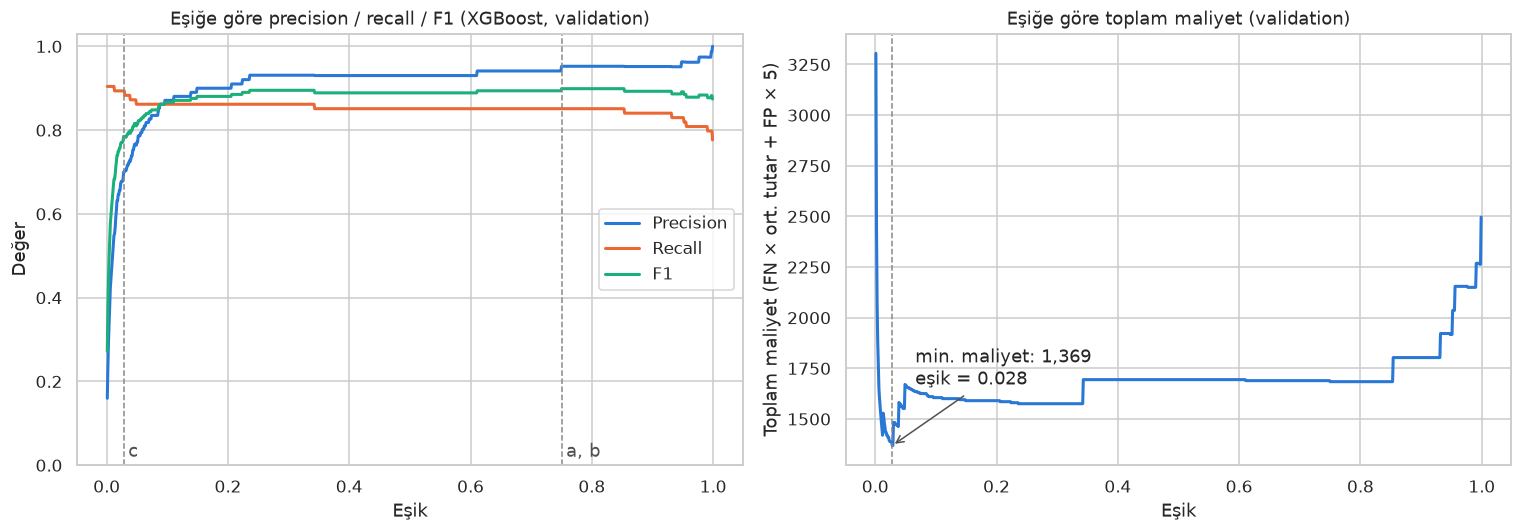

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: eşiğe göre precision, recall ve F1
axes[0].plot(thr_df["eşik"], thr_df["precision"], color=COLOR_NORMAL, linewidth=2, label="Precision")
axes[0].plot(thr_df["eşik"], thr_df["recall"], color=COLOR_FRAUD, linewidth=2, label="Recall")
axes[0].plot(thr_df["eşik"], thr_df["f1"], color=COLOR_THIRD, linewidth=2, label="F1")
# Aynı eşiğe düşen yöntemleri tek etikette birleştir (ör. "a, b")
markers = {}
for label, t in [("a", f1_row["eşik"]), ("b", recall_row["eşik"]), ("c", cost_row["eşik"])]:
    markers.setdefault(float(t), []).append(label)
for t, labels in markers.items():
    label = ", ".join(labels)
    axes[0].axvline(t, color=COLOR_MUTED, linestyle="--", linewidth=1)
    axes[0].annotate(label, (t, 0.02), xytext=(3, 0), textcoords="offset points", color="#52514e")
axes[0].set_xlabel("Eşik")
axes[0].set_ylabel("Değer")
axes[0].set_ylim(0, 1.03)
axes[0].set_title(f"Eşiğe göre precision / recall / F1 ({best_name}, validation)")
axes[0].legend(loc="center right")

# Sağ: eşiğe göre toplam maliyet
axes[1].plot(thr_df["eşik"], thr_df["maliyet"], color=COLOR_NORMAL, linewidth=2)
axes[1].axvline(cost_row["eşik"], color=COLOR_MUTED, linestyle="--", linewidth=1)
axes[1].annotate(f"min. maliyet: {cost_row['maliyet']:,.0f}\neşik = {cost_row['eşik']:.3f}",
                 (cost_row["eşik"], cost_row["maliyet"]), xytext=(15, 40), textcoords="offset points",
                 arrowprops={"arrowstyle": "->", "color": "#52514e"})
axes[1].set_xlabel("Eşik")
axes[1].set_ylabel("Toplam maliyet (FN × ort. tutar + FP × 5)")
axes[1].set_title("Eşiğe göre toplam maliyet (validation)")
plt.tight_layout()
plt.show()

**Okuma:** Eşik düştükçe recall artar, precision düşer. Bir FN, bir FP'den ~24 kat pahalı
olduğu için maliyetin minimumu düşük eşiklerde. Eşiğin 0,03 gibi küçük çıkması normal:
`scale_pos_weight` skorları yukarı iter, bu yüzden skorlar olasılık değil sıralama ölçüsüdür.

F1 ve maliyet eşiklerinin karşılaştırması:

In [24]:
# Maliyet eşiği (c), F1 eşiğine (a) göre ne kazandırıyor, ne kaybettiriyor?
extra_tp = int(cost_row["TP"] - f1_row["TP"])
extra_fp = int(cost_row["FP"] - f1_row["FP"])
print(f"(c) eşiği {cost_row['eşik']:.3f}, (a) eşiği {f1_row['eşik']:.3f}")
print(f"(c), (a)'ya göre {extra_tp} dolandırıcılığı fazladan yakalıyor -> "
      f"kurtarılan ≈ {extra_tp} × {COST_FN:.0f} = {extra_tp * COST_FN:,.0f}")
print(f"karşılığında {extra_fp} fazladan yanlış alarm veriyor -> "
      f"ek maliyet = {extra_fp} × {COST_FP:.0f} = {extra_fp * COST_FP:,.0f}")
print(f"Net toplam maliyet farkı: {f1_row['maliyet'] - cost_row['maliyet']:,.0f} (c lehine)")

(c) eşiği 0.028, (a) eşiği 0.750
(c), (a)'ya göre 4 dolandırıcılığı fazladan yakalıyor -> kurtarılan ≈ 4 × 119 = 475
karşılığında 32 fazladan yanlış alarm veriyor -> ek maliyet = 32 × 5 = 160
Net toplam maliyet farkı: 315 (c lehine)


### Seçim: maliyet eşiği (c)

- **İş hedefini doğrudan optimize ediyor.** F1 iki hatayı eşit sayar; burada kaçırılan bir
  dolandırıcılık ~119, bir yanlış alarm ise 5 birim. Yukarıdaki çıktıya göre (c), birkaç fazla
  yanlış alarm karşılığında daha fazla dolandırıcılık yakalıyor ve toplamda daha ucuz.
- **Keyfi bir hedef içermiyor.** (b)'deki %85 dışarıdan seçilmiş bir sayı ve bu veride (a) ile
  aynı eşiğe düşüyor. Maliyet yönteminin varsayımları ise açık ve tartışılabilir.

**Uyarı:** Validation setinde yalnızca 94 dolandırıcılık var, bu yüzden optimum eşik gürültülü.
Gerçek bir sistemde eşik daha büyük bir veriyle (ör. CV skorlarıyla) seçilmeli ve canlıda
izlenmeli.

Seçilen model: XGBoost
Seçilen eşik : 0.028  (c) Min. maliyet)


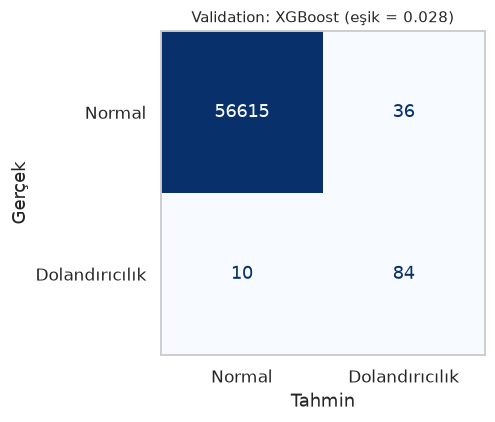

In [25]:
CHOSEN_METHOD = "c) Min. maliyet"
chosen_threshold = float(threshold_choices.loc[CHOSEN_METHOD, "eşik"])
print(f"Seçilen model: {best_name}")
print(f"Seçilen eşik : {chosen_threshold:.3f}  ({CHOSEN_METHOD})")

plot_confusion(y_val, (scores_val_best >= chosen_threshold).astype(int),
               f"Validation: {best_name} (eşik = {chosen_threshold:.3f})")

## 8. Test Setinde Final Değerlendirme

Model ve eşik sabitlendi; test setini **ilk ve tek kez** kullanıyoruz. Modeli train + validation
ile yeniden eğitmiyoruz, çünkü eşik bu modelin skorlarına göre seçildi.

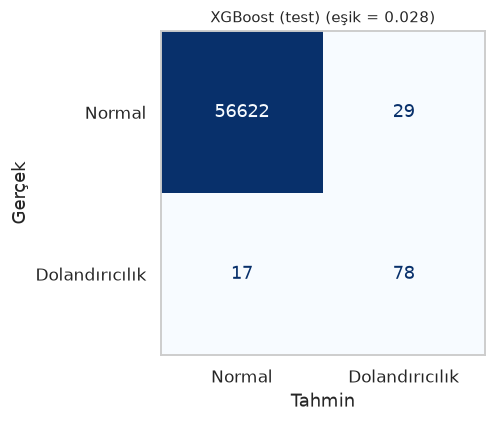

,validation,test
TP,84,78
FP,36,29
FN,10,17
TN,56615,56622
precision,0.7000,0.7290
recall,0.8936,0.8211
f1,0.7850,0.7723
pr_auc,0.8896,0.8320
roc_auc,0.9778,0.9721


In [26]:
test_metrics, test_scores = evaluate(
    f"{best_name} (test)", best_model, X_test, y_test, threshold=chosen_threshold, show_cm=True
)

# Aynı model ve eşiğin validation sonuçlarıyla yan yana
val_metrics_at_threshold = compute_metrics(best_name, y_val, scores_val_best, chosen_threshold)
final_table = pd.DataFrame(
    {"validation": val_metrics_at_threshold, "test": test_metrics}
).loc[["TP", "FP", "FN", "TN", "precision", "recall", "f1", "pr_auc", "roc_auc"]]
final_table

In [27]:
print(f"Test sonuçları ({best_name}, eşik = {chosen_threshold:.3f})")
print(f"  Precision : {test_metrics['precision']:.3f}")
print(f"  Recall    : {test_metrics['recall']:.3f}")
print(f"  F1        : {test_metrics['f1']:.3f}")
print(f"  PR-AUC    : {test_metrics['pr_auc']:.3f}")
print(f"  ROC-AUC   : {test_metrics['roc_auc']:.3f}")

Test sonuçları (XGBoost, eşik = 0.028)
  Precision : 0.729
  Recall    : 0.821
  F1        : 0.772
  PR-AUC    : 0.832
  ROC-AUC   : 0.972


Test skorlarının validation'dan biraz düşük çıkması beklenir: Seçim validation'da yapıldı (seçim
yanlılığı) ve ~95 pozitif örnekle birkaç işlem bile metrikleri oynatır. Raporlanacak sayılar test
sonuçlarıdır.

### Feature importance

Ağaç modellerinde `feature_importances_`, LR'de katsayıların mutlak değeri kullanılır. Bu değerler
nedensellik söylemez; ilişkili özellikler önemi aralarında paylaşabilir.

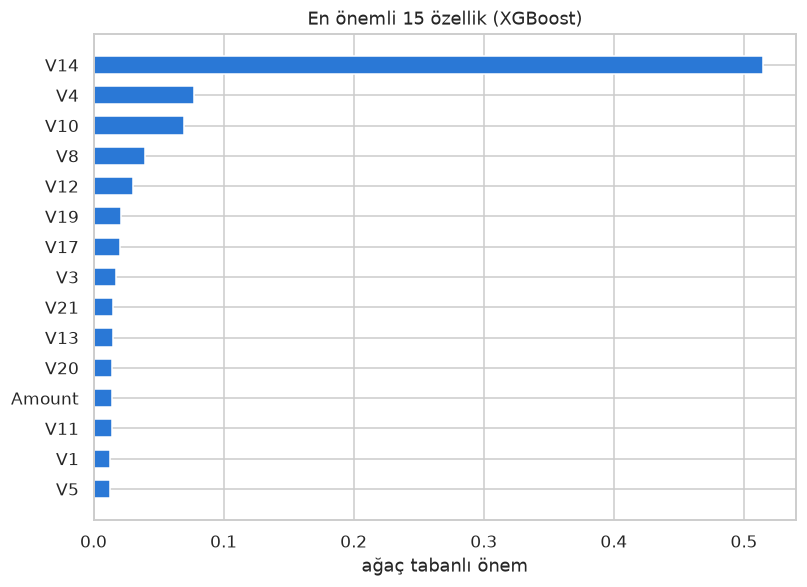

EDA'daki en güçlü 4 özelliğin modeldeki önem sırası:
  V17: 7. sırada
  V14: 1. sırada
  V12: 5. sırada
  V10: 3. sırada


In [28]:
def get_feature_importance(model, feature_names):
    # Pipeline ise içindeki modeli al; ağaçsa feature_importances_, doğrusalsa |katsayı| kullan
    estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model
    if hasattr(estimator, "feature_importances_"):
        values, kind = estimator.feature_importances_, "ağaç tabanlı önem"
    else:
        values, kind = np.abs(estimator.coef_[0]), "|katsayı|"
    return pd.Series(values, index=feature_names).sort_values(ascending=False), kind


importance, importance_kind = get_feature_importance(best_model, X_train.columns)
top_imp = importance.head(15)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(top_imp.index[::-1], top_imp.values[::-1], color=COLOR_NORMAL, height=0.6)
ax.set_xlabel(importance_kind)
ax.set_title(f"En önemli 15 özellik ({best_name})")
plt.tight_layout()
plt.show()

# EDA'da Class ile en güçlü ilişkili 4 özelliğin bu modeldeki önem sırası
importance_rank = importance.rank(ascending=False).astype(int)
print("EDA'daki en güçlü 4 özelliğin modeldeki önem sırası:")
for feat in top4:
    print(f"  {feat}: {importance_rank[feat]}. sırada")

EDA'daki güçlü özelliklerin bir kısmı burada daha aşağıda. Bunun sebebi, birbirleriyle ilişkili
olmaları: Ağaç bilgiyi `V14`'ten aldığında benzer özelliklere daha az önem verir. Ayrıca model,
korelasyonun yakalamadığı etkileşimleri kullanabilir (ör. `V4`).

### Kaçırılan dolandırıcılıkların analizi

Yakalanan dolandırıcılıkları, kaçırılanları ve normal işlemleri en önemli özelliklerde
karşılaştırıyoruz.

In [29]:
test_df = X_test_raw.copy()  # orijinal (ölçeklenmemiş) değerler
test_df["Class"] = y_test
test_df["skor"] = test_scores
test_df["tahmin"] = (test_scores >= chosen_threshold).astype(int)
test_df["Hour"] = (test_df["Time"] // 3600 % 24).astype(int)

frauds = test_df[test_df["Class"] == 1]
caught = frauds[frauds["tahmin"] == 1]
missed = frauds[frauds["tahmin"] == 0]
normals = test_df[test_df["Class"] == 0]
print(f"Test setindeki dolandırıcılık: {len(frauds)}  ->  yakalanan: {len(caught)}, kaçırılan: {len(missed)}")

# En önemli 4 V özelliği + tutar + saat için grupların medyanları
top_v = [c for c in importance.index if c.startswith("V")][:4]
analysis_cols = top_v + ["Amount", "Hour", "skor"]
pd.DataFrame({
    "Yakalanan dolandırıcılık": caught[analysis_cols].median(),
    "Kaçırılan dolandırıcılık": missed[analysis_cols].median(),
    "Normal işlem": normals[analysis_cols].median(),
}).rename_axis("medyan")

Test setindeki dolandırıcılık: 95  ->  yakalanan: 78, kaçırılan: 17


,Yakalanan dolandırıcılık,Kaçırılan dolandırıcılık,Normal işlem
medyan,,,
V14,-6.8479,-0.4317,0.0572
V4,4.4500,1.0648,-0.0252
V10,-4.7219,-0.2837,-0.0905
V8,0.9284,-0.2334,0.0203
Amount,31.9900,1.1800,21.6000
Hour,11.0000,16.0000,14.0000
skor,1.0000,0.0000,0.0000


In [30]:
# Kaçırılan dolandırıcılıkların tek tek listesi (skora göre azalan)
missed[analysis_cols].sort_values("skor", ascending=False)

,V14,V4,V10,V8,Amount,Hour,skor
228883,-4.9426,4.5089,-0.6285,-0.2812,2.2200,16,0.0171
68058,-2.3767,3.1618,-0.2837,0.4114,0.7600,14,0.0120
239334,-4.2525,4.6174,-0.3739,0.0895,1.0000,17,0.0044
231118,-3.6888,0.6950,-0.8872,-6.3331,8.0000,16,0.0011
153692,3.4424,1.0648,1.7859,-0.4465,0.9200,4,0.0006
107830,1.0276,2.8914,0.3242,-2.4216,0.7600,19,0.0002
101128,-0.4317,0.0537,0.5176,-0.3133,320.0000,18,0.0001
67805,0.5789,0.8478,-0.1501,0.0233,519.9000,14,0.0001
248322,0.9850,0.1633,-1.1345,-0.4710,1096.9900,18,0.0000
130779,0.5215,3.1282,0.2696,-2.2038,0.2000,22,0.0000


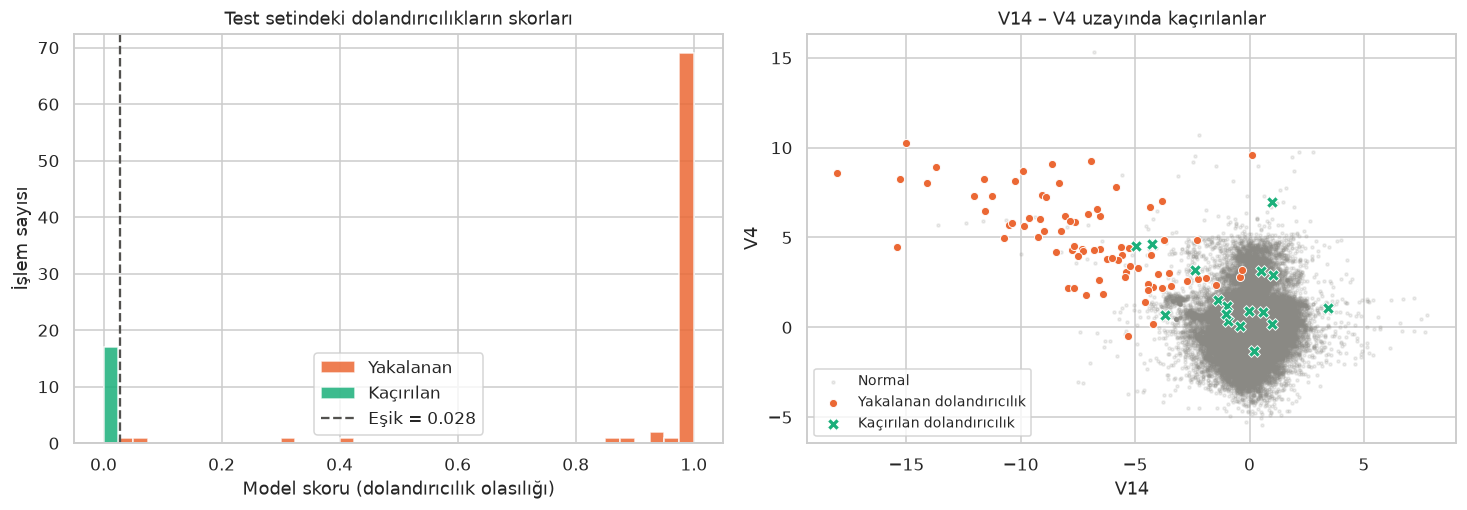

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Sol: dolandırıcılıkların model skorları ve eşik
bins = np.linspace(0, 1, 41)
axes[0].hist(caught["skor"], bins=bins, color=COLOR_FRAUD, alpha=0.85, label="Yakalanan")
axes[0].hist(missed["skor"], bins=bins, color=COLOR_THIRD, alpha=0.85, label="Kaçırılan")
axes[0].axvline(chosen_threshold, color="#52514e", linestyle="--", linewidth=1.5,
                label=f"Eşik = {chosen_threshold:.3f}")
axes[0].set_xlabel("Model skoru (dolandırıcılık olasılığı)")
axes[0].set_ylabel("İşlem sayısı")
axes[0].set_title("Test setindeki dolandırıcılıkların skorları")
axes[0].legend()

# Sağ: en önemli iki V özelliğinde normal / yakalanan / kaçırılan
f1_name, f2_name = top_v[:2]
axes[1].scatter(normals[f1_name], normals[f2_name], s=4, color=COLOR_MUTED, alpha=0.15, label="Normal")
axes[1].scatter(caught[f1_name], caught[f2_name], s=28, color=COLOR_FRAUD,
                edgecolor="white", linewidth=0.6, label="Yakalanan dolandırıcılık")
axes[1].scatter(missed[f1_name], missed[f2_name], s=60, color=COLOR_THIRD, marker="X",
                edgecolor="white", linewidth=0.6, label="Kaçırılan dolandırıcılık")
axes[1].set_xlabel(f1_name)
axes[1].set_ylabel(f2_name)
axes[1].set_title(f"{f1_name} – {f2_name} uzayında kaçırılanlar")
axes[1].legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

**Gözlem:** Kaçırılanlar en önemli özelliklerde normal işlemlere benziyor ve normal işlem bulutunun
içinde kalıyor. Çoğu da çok küçük tutarlı (olası "deneme" işlemleri). Bunları yakalamak için daha
iyi bir model değil, **yeni bilgi** gerekir: işlem geçmişi, cihaz, konum gibi.

### Yakalanan ve kaçırılan tutar

Recall işlem sayısına bakar; iş açısından önemli olan ise kurtarılan **para**.

In [32]:
total_fraud_amount = frauds["Amount"].sum()
caught_amount = caught["Amount"].sum()
missed_amount = missed["Amount"].sum()
fp_count = test_metrics["FP"]

amount_summary = pd.DataFrame(
    {
        "işlem sayısı": [len(frauds), len(caught), len(missed)],
        "toplam tutar": [total_fraud_amount, caught_amount, missed_amount],
        "tutarın payı (%)": [100.0, caught_amount / total_fraud_amount * 100, missed_amount / total_fraud_amount * 100],
    },
    index=["Tüm dolandırıcılıklar", "Yakalanan", "Kaçırılan"],
)
display(amount_summary.style.format({"toplam tutar": "{:,.2f}", "tutarın payı (%)": "{:.1f}"}))

cost_without_model = total_fraud_amount
cost_with_model = missed_amount + fp_count * COST_FP
print(f"Tutar bazında recall: %{caught_amount / total_fraud_amount * 100:.1f} "
      f"(işlem bazında recall: %{test_metrics['recall'] * 100:.1f})")
print(f"Model olmadan kayıp                         : {cost_without_model:,.2f}")
print(f"Modelle kayıp (kaçırılan tutar + {fp_count} FP × {COST_FP:.0f}) : {cost_with_model:,.2f}")
print(f"Tahmini tasarruf                            : {cost_without_model - cost_with_model:,.2f}")

,işlem sayısı,toplam tutar,tutarın payı (%)
Tüm dolandırıcılıklar,95,"14,766.31",100.0
Yakalanan,78,"12,155.78",82.3
Kaçırılan,17,"2,610.53",17.7


Tutar bazında recall: %82.3 (işlem bazında recall: %82.1)
Model olmadan kayıp                         : 14,766.31
Modelle kayıp (kaçırılan tutar + 29 FP × 5) : 2,755.53
Tahmini tasarruf                            : 12,010.78


## 9. Bonus

### 9.1 SMOTE + StratifiedKFold cross-validation

Tek bir validation seti gürültülüdür. Cross-validation, k katmanın ortalamasını ve standart
sapmasını verir. SMOTE CV'den **önce** uygulanırsa, sentetik örnekler validation katmanındaki
gerçek örneklerden üretilir ve skor şişer. Doğru yöntem, ölçekleme + SMOTE + modeli tek bir
`imblearn` Pipeline'a koymaktır; `cross_validate` her katmanda pipeline'ı yalnızca train kısmına
fit eder. Yalnızca train setini kullanıyor, doğru ve yanlış yöntemi karşılaştırıyoruz.

In [33]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

# DOĞRU: ölçekleme + SMOTE + model tek pipeline'da, her katmanda yalnızca train kısmına fit
preprocess = ColumnTransformer(
    [("robust", RobustScaler(), SCALE_COLS)], remainder="passthrough"
)
cv_pipeline = ImbPipeline([
    ("scale", preprocess),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv_correct = cross_validate(cv_pipeline, X_train_raw, y_train, cv=skf, scoring=scoring, n_jobs=-1)

# YANLIŞ (yalnızca gösterim için): SMOTE önce tüm train setine uygulanıyor, sonra CV
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
cv_leaky = cross_validate(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    X_res, y_res, cv=skf, scoring=scoring, n_jobs=-1,
)


def summarize_cv(cv_result):
    # Her metrik için "ortalama ± standart sapma" metni üretir
    return {m: f"{cv_result[f'test_{m}'].mean():.3f} ± {cv_result[f'test_{m}'].std():.3f}" for m in scoring}


pd.DataFrame(
    {"Doğru: SMOTE pipeline içinde": summarize_cv(cv_correct),
     "Yanlış: SMOTE CV'den önce (leakage)": summarize_cv(cv_leaky)}
).T

,precision,recall,f1,roc_auc,pr_auc
Doğru: SMOTE pipeline içinde,0.051 ± 0.002,0.908 ± 0.075,0.097 ± 0.003,0.982 ± 0.015,0.738 ± 0.055
Yanlış: SMOTE CV'den önce (leakage),0.969 ± 0.000,0.928 ± 0.002,0.948 ± 0.001,0.993 ± 0.000,0.993 ± 0.000


**Yorum:** Doğru yöntemin sonuçları, 5. bölümdeki LR + SMOTE sonuçlarıyla uyumlu. Yanlış yöntem
skorları ciddi şekilde şişiriyor, çünkü validation katmanları sentetik örneklerle dolu ve 1:1
dengeli. PR-AUC'nin standart sapması da tek bir validation skorunun ne kadar oynayabileceğini
gösteriyor.

### 9.2 IsolationForest ile etiketsiz anomali tespiti

Gerçek hayatta etiket çoğu zaman yoktur ya da geç gelir. IsolationForest etiket kullanmaz; az
sayıda bölmeyle izole edilebilen noktaları anomali sayar. Modeli `X_train` ile, etiketsiz olarak
eğitiyoruz; `contamination` = train'deki dolandırıcılık oranı. Test seti kapandığı için
değerlendirmeyi validation'da yapıyoruz.

In [34]:
train_fraud_rate = float(y_train.mean())
iso = IsolationForest(
    n_estimators=300, contamination=train_fraud_rate, n_jobs=-1, random_state=RANDOM_STATE
)
iso.fit(X_train)  # etiket yok!

# score_samples: yüksek = normal. İşareti çevirince yüksek = daha anormal olur.
iso_scores_val = -iso.score_samples(X_val)
iso_threshold = -iso.offset_  # contamination oranına karşılık gelen sınır
iso_metrics = compute_metrics("IsolationForest (etiketsiz)", y_val, iso_scores_val, iso_threshold)

comparison = pd.DataFrame([
    iso_metrics,
    compute_metrics(f"{best_name} (denetimli, eşik 0,5)", y_val, scores_val_best, 0.5),
]).set_index("model").drop(columns="eşik")
comparison

,TP,FP,FN,TN,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,,
IsolationForest (etiketsiz),19,60,75,56591,0.2405,0.2021,0.2197,0.9447,0.1504
"XGBoost (denetimli, eşik 0,5)",80,6,14,56645,0.9302,0.8511,0.8889,0.9778,0.8896


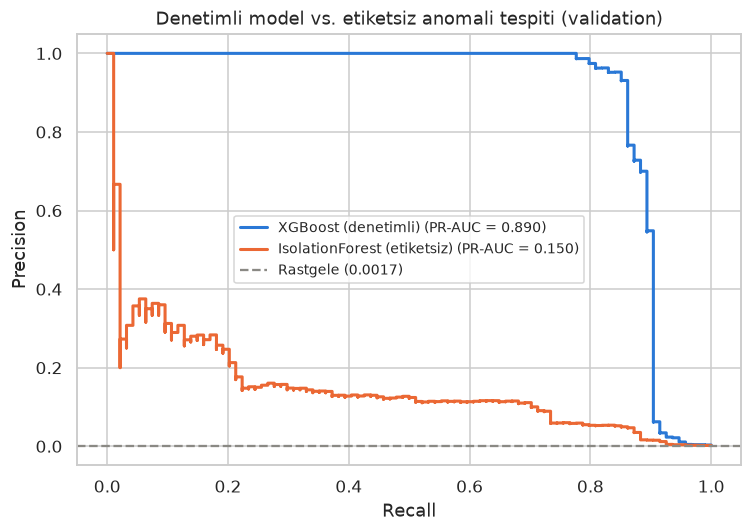

In [35]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, scores, color in [
    (f"{best_name} (denetimli)", scores_val_best, COLOR_NORMAL),
    ("IsolationForest (etiketsiz)", iso_scores_val, COLOR_FRAUD),
]:
    prec, rec, _ = precision_recall_curve(y_val, scores)
    ap = average_precision_score(y_val, scores)
    ax.plot(rec, prec, color=color, linewidth=2, drawstyle="steps-post", label=f"{name} (PR-AUC = {ap:.3f})")
ax.axhline(y_val.mean(), linestyle="--", color=COLOR_MUTED, label=f"Rastgele ({y_val.mean():.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Denetimli model vs. etiketsiz anomali tespiti (validation)")
ax.legend(loc="center", fontsize=9)
plt.tight_layout()
plt.show()

**Yorum:** IsolationForest etiket görmeden rastgele tahminin çok üstüne çıkıyor (PR-AUC'si
rastgelenin ~90 katı), ama denetimli modelin çok gerisinde. Her aykırı işlem dolandırıcılık
değil, her dolandırıcılık da aykırı değil. Etiket varsa denetimli öğrenme açık ara daha iyi;
etiketsiz yöntemler ise yeni dolandırıcılık türleri için erken uyarı olarak değerli.

## 10. Sonuç

Veri aşırı dengesiz (%0,17): Her şeye "normal" diyen model %99,83 accuracy alırken hiç
dolandırıcılık yakalamıyor, bu yüzden precision, recall ve PR-AUC kullandık. Validation setinde
en iyi model XGBoost oldu (PR-AUC 0,890); Random Forest ~0,88'de, Logistic Regression ~0,80'de
kaldı. Dengeleme yöntemleri LR'nin PR-AUC'sini artırmadı, yalnızca 0,5 eşiğinde recall'u
yükseltip precision'ı düşürdü. ROC-AUC tüm modellerde 0,95–0,98 aralığındaydı ve PR-AUC'si 0,49
olan modeli 0,89 olandan ayıramadı. Maliyete göre seçilen 0,028 eşiğiyle XGBoost, test setindeki
95 dolandırıcılığın 78'ini yakaladı (recall 0,82, precision 0,73, F1 0,77, PR-AUC 0,83) ve
dolandırıcılık tutarının %82'sini kurtardı. Kaçırılanlar normal işlemlere benziyor ve çoğu küçük
tutarlı; bunları yakalamak için yeni özellikler gerekir. Bonus bölümde iki şey daha gördük:
SMOTE'u CV'den önce uygulamak PR-AUC'yi 0,74'ten 0,99'a şişiriyor, IsolationForest ise
(PR-AUC 0,15) denetimli modelin çok gerisinde kalıyor.